**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Jesus Gomez-Braña Gonzalez
*   MATRÍCULA: A01841439

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
  - Existen 8 columnas numericas y 5 de texto

In [ ]:
loan_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Ciencia de datos/Actividad4/personal_loan.csv', index_col='ID')
filas_originales = loan_df.shape[0]
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
En todas las columnas numericas se puede observar que la media y la desviacion estandar son valores comunes, mientras que la columna de ingresos e hipoteca tiene valores cesgados (media mucho mayor a la mediana) por lo tanto se decidio optar como referencia para actoar valores que no representaran a la poblacion general.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [ ]:
loan_df[loan_df.columns[loan_df.dtypes != 'object']].describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [ ]:
loan_df[loan_df.Age > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


- Al observar los datos mayores a 100 años estos no son plausibles, tambien se nota que columnas que son de texto tambien se encuentran con valores numericos y booleanos, por lo cual seria buena idea inspeccionar los valores unicos de esas columnas al igual que filtrar estos datos de edades irrealistas

In [ ]:
loan_df = loan_df[loan_df.Age < 100]
max(loan_df.Age)

67

In [ ]:
loan_df['Personal Loan'].unique()

array(['0', 'No', 'Yes', '1'], dtype=object)

In [ ]:
loan_df['Securities Account'].unique()

array(['Yes', '0', 'No', '1'], dtype=object)

In [ ]:
loan_df['CD Account'].unique()

array(['No', '0', '1', 'Yes'], dtype=object)

In [ ]:
loan_df['Online'].unique()

array(['0', 'No', '1', 'Yes'], dtype=object)

In [ ]:
loan_df['CreditCard'].unique()

array(['0', '1', 'Yes', 'No'], dtype=object)

- El que estas columnas siempre tengan valores booleanos vale la pena convertir las columnas en verdaderos booleanos para haceros mas faciles de trabajar

In [ ]:
def cast_to_boolean(x:str)->bool:
  if x == 'No' or x == '0':
    return False
  elif x == 'Yes' or x == '1':
    return True
  else:
    raise Exception('Invalid value')

for column in loan_df.columns:
  if loan_df[column].dtype == object:
    loan_df[column] = loan_df[column].apply(cast_to_boolean)
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5034 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5034 non-null   int64  
 1   Experience          5034 non-null   int64  
 2   Income              5034 non-null   int64  
 3   ZIP Code            5034 non-null   int64  
 4   Family              5034 non-null   int64  
 5   CCAvg               5034 non-null   float64
 6   Education           5034 non-null   float64
 7   Mortgage            5034 non-null   int64  
 8   Personal Loan       5034 non-null   bool   
 9   Securities Account  5034 non-null   bool   
 10  CD Account          5034 non-null   bool   
 11  Online              5034 non-null   bool   
 12  CreditCard          5034 non-null   bool   
dtypes: bool(5), float64(2), int64(6)
memory usage: 378.5 KB


- Ahora se buscara determinar si existen valores extraordinarios en alguna distribucion de nuestros atributos para asi no utilizar datos que puedan influir en el estudio de comportamiento promedio de los sujetos

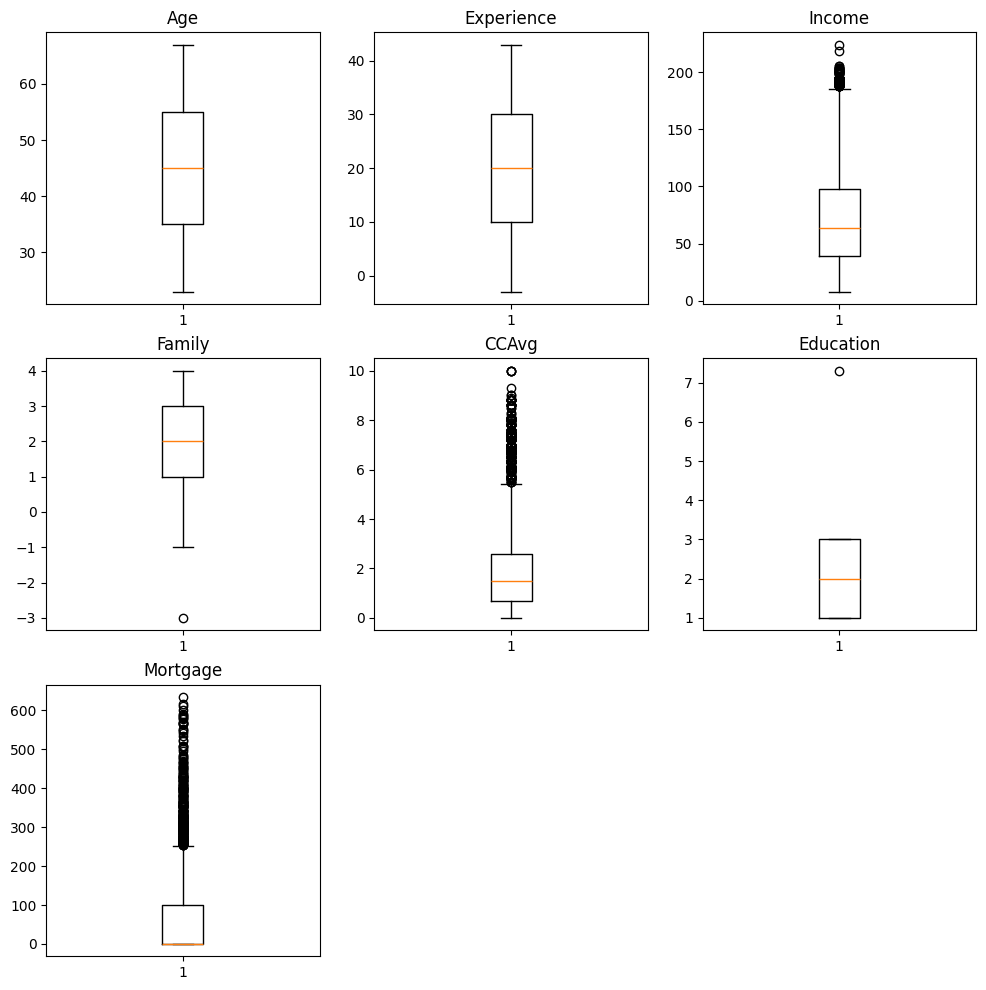

In [ ]:
def plot_box_matrix():
  fig = plt.figure(figsize=(12, 12))
  counter = 0
  for column in loan_df.columns:
    if loan_df[column].dtype == bool or column == 'ZIP Code':
      continue
    sub_fig = fig.add_subplot(3,3, counter + 1)
    sub_fig.set_title(column)
    sub_fig.boxplot(loan_df[column])
    counter += 1
  fig.show()

plot_box_matrix()

- Se observa que la hipoteca, ingresos y la edad de vida laboral son las variables con mayores valores extraordinarios por lo cual se utilizaran para filtrar. Se filtraran los valores extremos al tomar el valores de las colas del box plot como limites. El cual se calcula utilizando el 3er cuartil mas 1.5 veces el rango intercuartilico

- Tambien es imposible tener una cantidad no positiva de familiares

- Se elimina el outlier de educacion que tiene un numero muy extremo a comparacion de los demas

In [ ]:
loan_df = loan_df[loan_df.Mortgage < loan_df.Mortgage.quantile(0.75)+1.5*loan_df.Mortgage.quantile([0.25,0.75]).diff().iloc[-1]]
loan_df = loan_df[loan_df.CCAvg < loan_df.CCAvg.quantile(0.75)+1.5*loan_df.CCAvg.quantile([0.25,0.75]).diff().iloc[-1]]
loan_df = loan_df[loan_df.Income < loan_df.Income.quantile(0.75)+1.5*loan_df.Income.quantile([0.25,0.75]).diff().iloc[-1]]
loan_df = loan_df[loan_df.Family > 0]
loan_df = loan_df[loan_df.Education < 4]

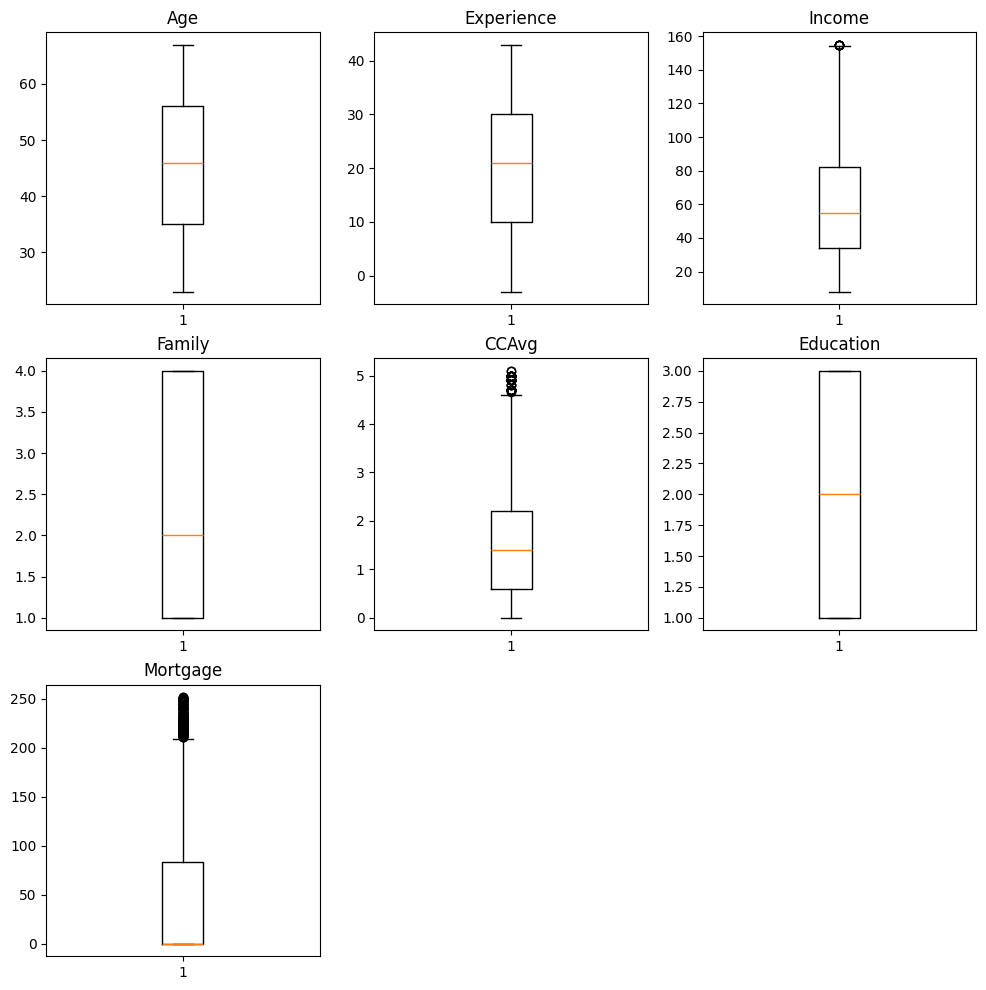

In [ ]:
plot_box_matrix()

La cantidad de registros que quedaron fueron de `4283`

lo cual representa `85.03%` de la muestra

eliminandose un total de `754` datos

In [ ]:
loan_df.shape[0]

4283

In [ ]:
loan_df.shape[0] / filas_originales * 100

85.03077228509032

In [ ]:
loan_df.shape[0] - filas_originales

-754

In [ ]:
loan_df[loan_df.columns[loan_df.dtypes != bool]].describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,4283.000000,4283.000000,4283.000000,4283.000000,4283.000000,4283.000000,4283.000000,4283.000000
mean,45.543311,20.283913,60.810180,93147.777025,2.456456,1.505228,1.930423,38.827691
std,11.494437,11.513885,33.619087,2180.776062,1.159876,1.114800,0.835244,68.058769
min,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,34.000000,91910.500000,1.000000,0.600000,1.000000,0.000000
50%,46.000000,21.000000,55.000000,93407.000000,2.000000,1.400000,2.000000,0.000000
75%,56.000000,30.000000,82.000000,94608.000000,4.000000,2.200000,3.000000,84.000000
max,67.000000,43.000000,155.000000,96651.000000,4.000000,5.100000,3.000000,252.000000


3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
   - Falso es el valor mas comun para todas las variables categoricas con la proporcion de verdaderos mas alta siendo la de Online con 59%
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.
   - Realice este paso en el ejercicio anterior

In [ ]:
loan_df[loan_df.columns[loan_df.dtypes == bool]].describe()

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4283,4283,4283,4283,4283
unique,2,2,2,2,2
top,False,False,False,True,False
freq,4081,3834,4103,2544,3020


In [ ]:
loan_df[loan_df["Personal Loan"] == False].shape

(4081, 13)

In [ ]:
loan_df[loan_df.columns[loan_df.dtypes == bool]].value_counts()

Personal Loan  Securities Account  CD Account  Online  CreditCard
False          False               False       True    False         1525
                                               False   False         1035
                                               True    True           603
                                               False   True           442
               True                False       True    False          174
                                               False   False          123
True           False               False       True    False           73
False          True                True        True    True            64
               False               True        True    True            54
True           False               False       False   False           53
False          True                False       False   True            42
True           False               False       False   True            28
                                   True        True    True            18
False          True                True        True    False           14
True           True                True        True    False           14
False          True                True        False   True             5
True           True                False       False   False            5
                                   True        False   True             3
                                               True    True             3
               False               True        True    False            2
               True                True        False   False            2
               False               True        False   True             1
Name: count, dtype: int64

In [ ]:
filtered = loan_df[loan_df.columns[loan_df.dtypes == bool]]
for column in filtered.columns:
  print(filtered[column].value_counts())
  print(f"Proportion = {round(filtered[column][filtered[column] == True].shape[0]/filtered.shape[0],2)*100}%")


Personal Loan
False    4081
True      202
Name: count, dtype: int64
Proportion = 5.0%
Securities Account
False    3834
True      449
Name: count, dtype: int64
Proportion = 10.0%
CD Account
False    4103
True      180
Name: count, dtype: int64
Proportion = 4.0%
Online
True     2544
False    1739
Name: count, dtype: int64
Proportion = 59.0%
CreditCard
False    3020
True     1263
Name: count, dtype: int64
Proportion = 28.999999999999996%


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
  - Si los hay
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [ ]:
loan_df.duplicated().sum()

np.int64(27)

In [ ]:
loan_df = loan_df[~loan_df.duplicated()]
loan_df.reset_index(drop=True, inplace=True)
loan_df.duplicated().sum()

np.int64(0)

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [ ]:
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')
loan_df['Education'] = loan_df['Education'].astype('category').cat.set_categories([1,2,3], ordered=True)
for column in loan_df.columns:
  if loan_df[column].dtype == bool:
    loan_df[column] = loan_df[column].astype('category')
loan_df.dtypes

,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


In [ ]:
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

  - Age: Aproximadamente simetrica y platicurtica
  - Income: Ligeramente sesgado positivamente y aproximadamente mesocurtica
  - Mortgage: Asimetricamente sesgado positivamente y leptocurtica

In [ ]:
loan_df[num_cols].describe()

,Age,Experience,Income,Family,CCAvg,Mortgage
count,4256.000000,4256.000000,4256.000000,4256.000000,4256.000000,4256.000000
mean,45.529370,20.270442,60.799107,2.456297,1.505449,38.765038
std,11.498269,11.518276,33.633845,1.159021,1.114289,68.019896
min,23.000000,-3.000000,8.000000,1.000000,0.000000,0.000000
25%,35.000000,10.000000,34.000000,1.000000,0.600000,0.000000
50%,46.000000,20.000000,55.000000,2.000000,1.400000,0.000000
75%,56.000000,30.000000,82.000000,4.000000,2.200000,84.000000
max,67.000000,43.000000,155.000000,4.000000,5.100000,252.000000


In [ ]:
loan_df[num_cols].skew()

,0
Age,-0.046520
Experience,-0.043946
Income,0.667479
Family,0.067242
CCAvg,0.829487
Mortgage,1.491123


In [ ]:
loan_df[num_cols].kurt()

,0
Age,-1.168353
Experience,-1.137663
Income,-0.184994
Family,-1.446415
CCAvg,0.282608
Mortgage,0.882055


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
   - Si coincide con lo esperado, al ser variables categoricas estas tienen una cantidad finitas de posibilidades mientras que variables numericas pueden tener intervalos infinitos. Tambien al tener columnas booleanas solo pueden tener 2 posibles resultados. Solamente codigos postales que tiene una alta cantidad de combinaciones tiene una distribucion con muchos bins igual que la variables numericas.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

  - La posicion de la media conforme a la mediana muestra la direccion hacia la que se esta cesgando la distribucion. La mediana se mantendra mas al centro de todo el conjunto de valores (El punto medio del conjunto) mientras que la media es el punto de balance del conjunto. Por lo tanto un valor excepcional puede moverlo hacia la derecha o izquierda de la mediana. Cuando la media es mayor a la mediana se dice que se tiene un sesgo positivo y si es menor un sesgo negativo.
  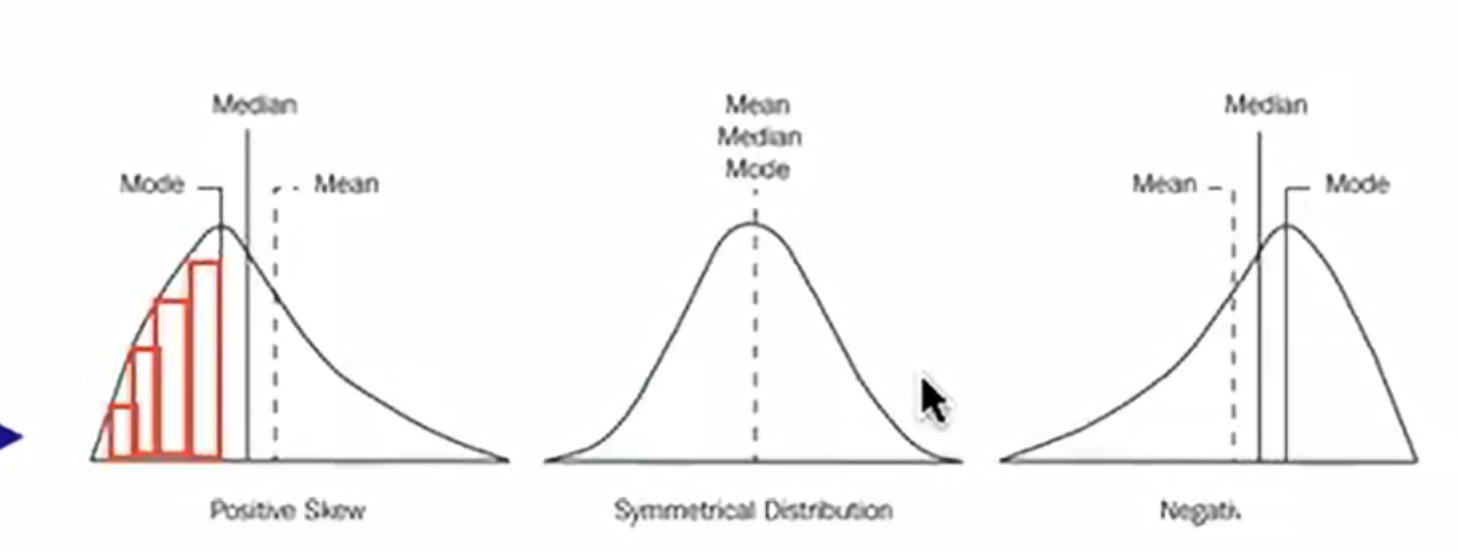

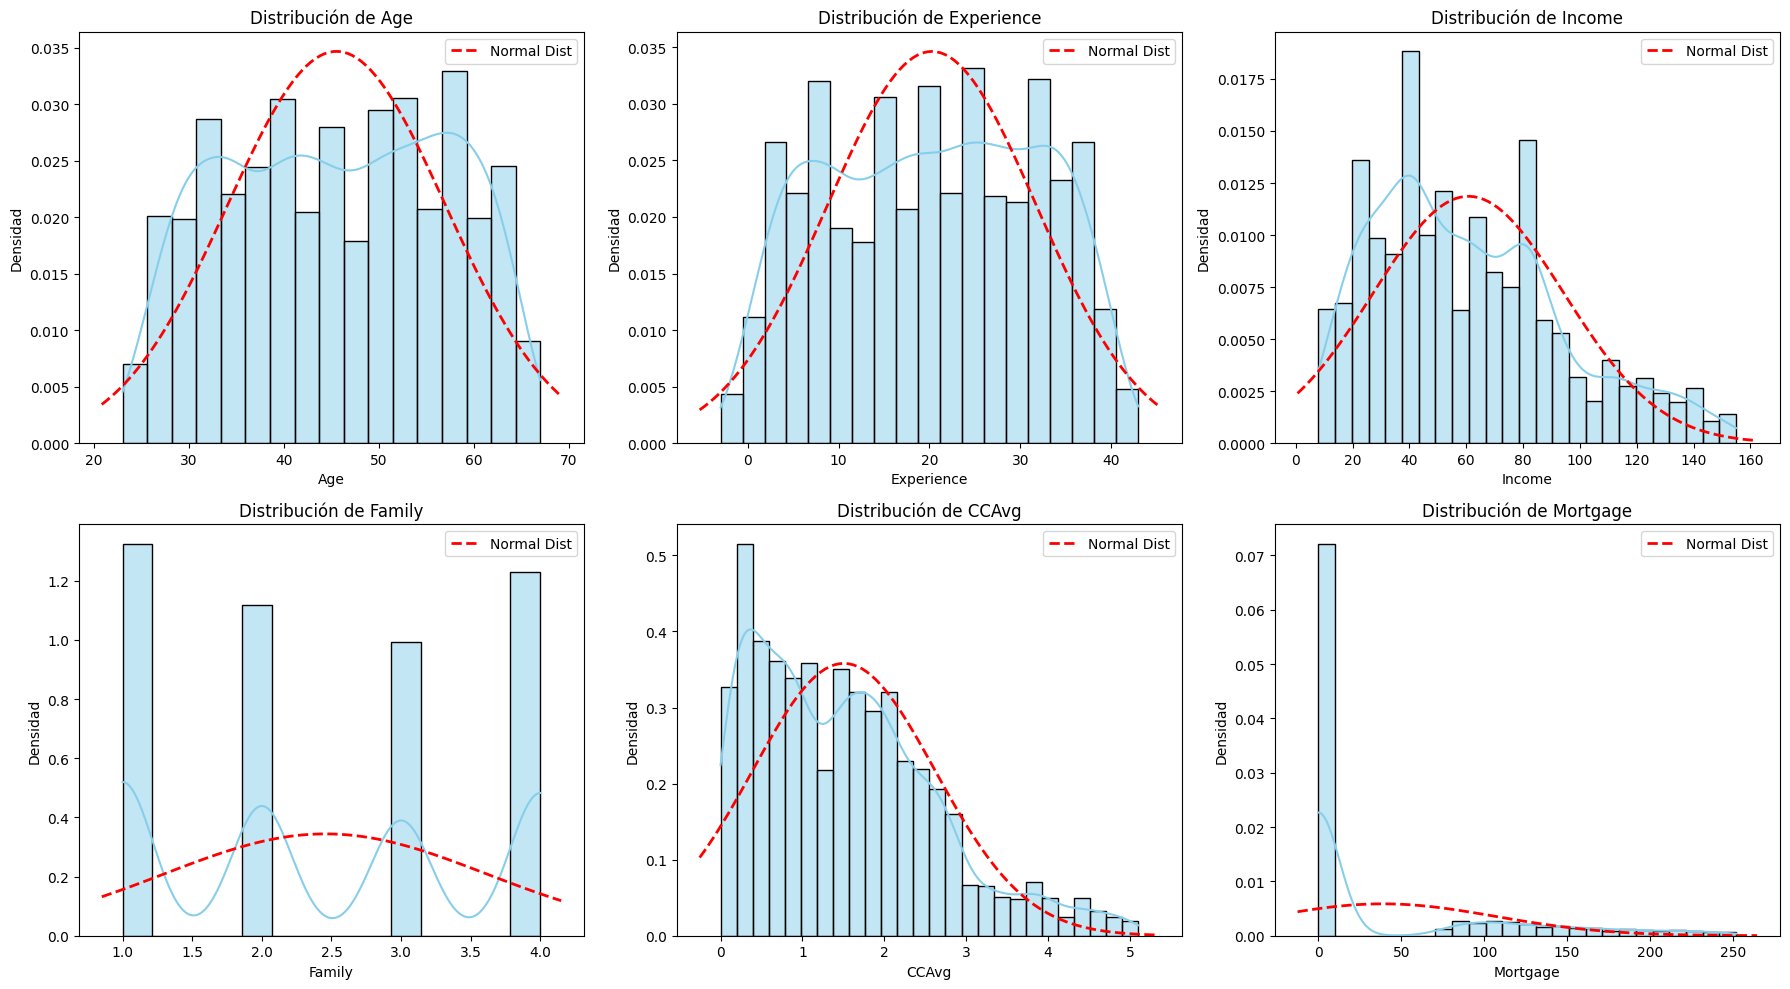

In [ ]:
# Configuramos la cuadrícula de 2 filas y 3 columnas para las 6 variables numéricas
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, column in enumerate(num_cols):
    ax = axes[i]

    # Dibujar el histograma y la curva KDE usando Seaborn
    sns.histplot(loan_df[column], kde=True, stat="density", color="skyblue", ax=ax)

    # Calcular los parámetros para la curva de distribución normal de referencia
    mu, std = loan_df[column].mean(), loan_df[column].std()
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mu, std)

    # Graficar la curva normal de referencia
    ax.plot(x, p, 'r--', linewidth=2, label='Normal Dist')

    # Configuración de etiquetas y títulos
    ax.set_title(f'Distribución de {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Densidad')
    ax.legend()

plt.tight_layout()
plt.show()

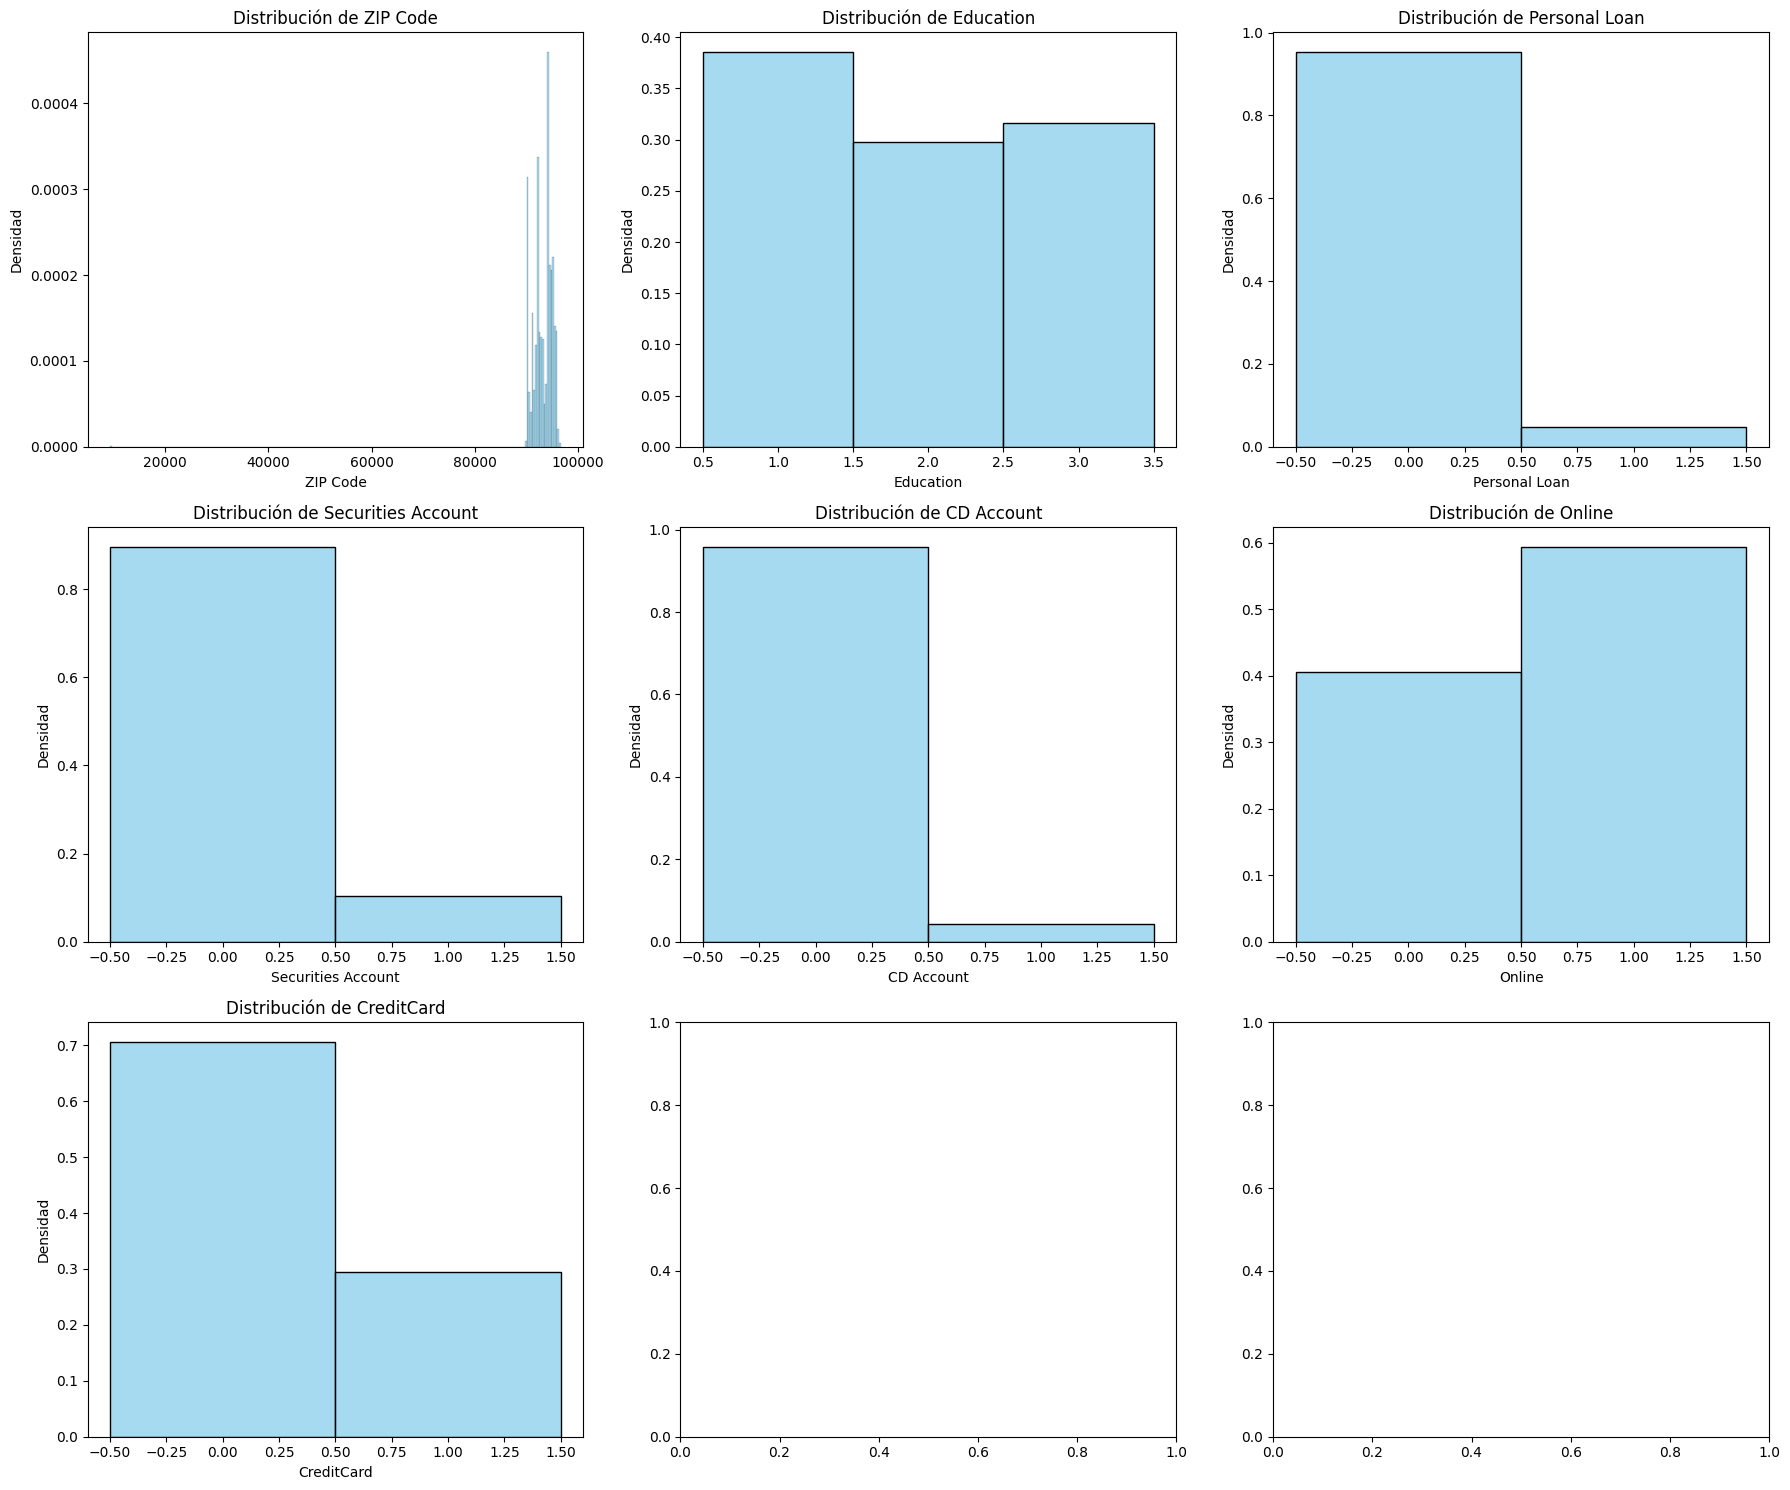

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, column in enumerate(cat_cols):
    ax = axes[i]

    # Dibujar el gráfico de distribución usando Seaborn
    sns.histplot(loan_df[column], kde=False, stat="density", color="skyblue", ax=ax)

    # Configuración de etiquetas y títulos
    ax.set_title(f'Distribución de {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Densidad')



plt.tight_layout()
plt.show()

<Axes: >

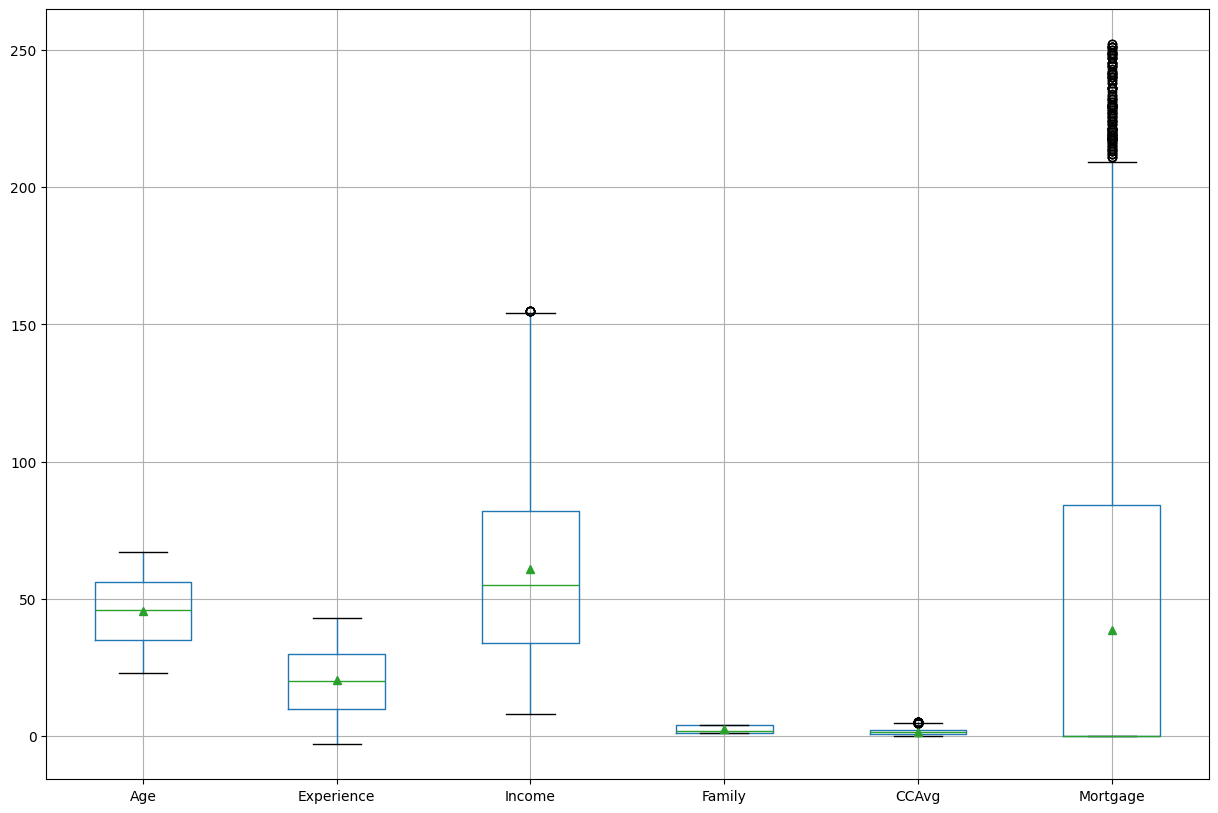

In [ ]:
loan_df[num_cols].boxplot(
    figsize=(15, 10),
    showmeans=True,
)

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [ ]:
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4256,4256,4256,4256,4256,4256,4256
unique,466,3,2,2,2,2,2
top,94720,1,False,False,False,True,False
freq,148,1641,4056,3811,4076,2527,3004


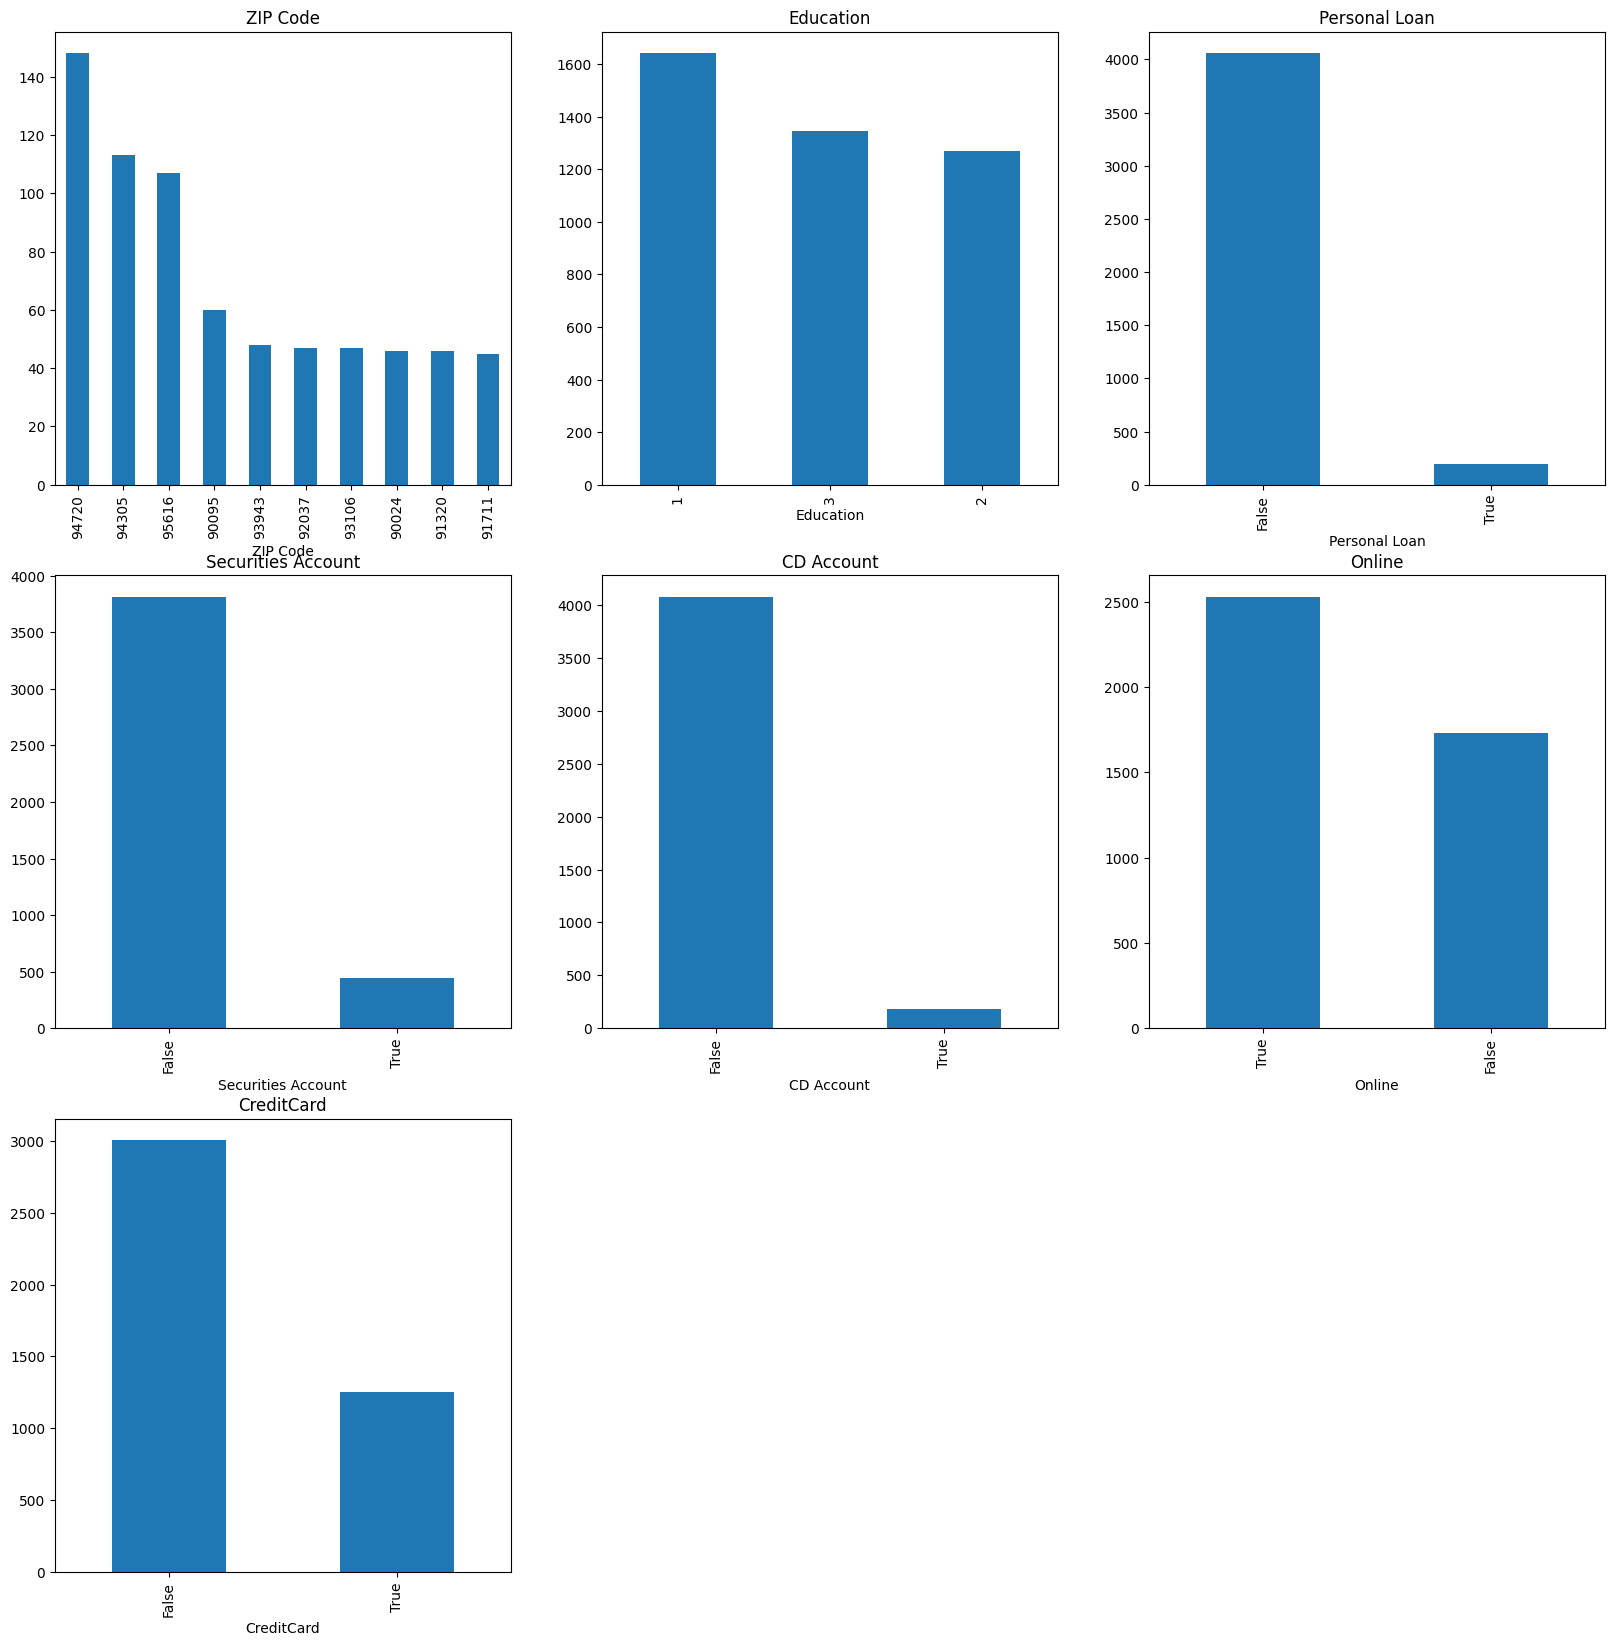

In [ ]:
fig = plt.figure(figsize=(20,20))
counter = 1
for column in cat_cols:
  ax = fig.add_subplot(int(round(len(cat_cols)/3,0))+1,3,counter)
  loan_df[column].value_counts()[:10].plot(kind='bar')
  ax.set_title(column)
  counter += 1
fig.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.

  - La relación entre la edad (Age) y la experiencia (Experience) está fuertemente correlacionada de manera positiva.
  - La edad (Age) y los ingresos (Income) no parecen tener ninguna correlación en absoluto.
  - En los gráficos de dispersión de la hipoteca (Mortgage), se pueden ver claramente dos grupos: aquellos que tienen una hipoteca y aquellos que no la tienen.
  - Los ingresos (Income) y el uso promedio de la tarjeta de crédito (CCAvg) están correlacionados positivamente.
  - Los ingresos (Income) y la hipoteca (Mortgage) están correlacionados positivamente si se excluye a las personas que no tienen hipoteca.

* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

  - Si, corresponde a lo esperado que se redacto en el apartado anterior

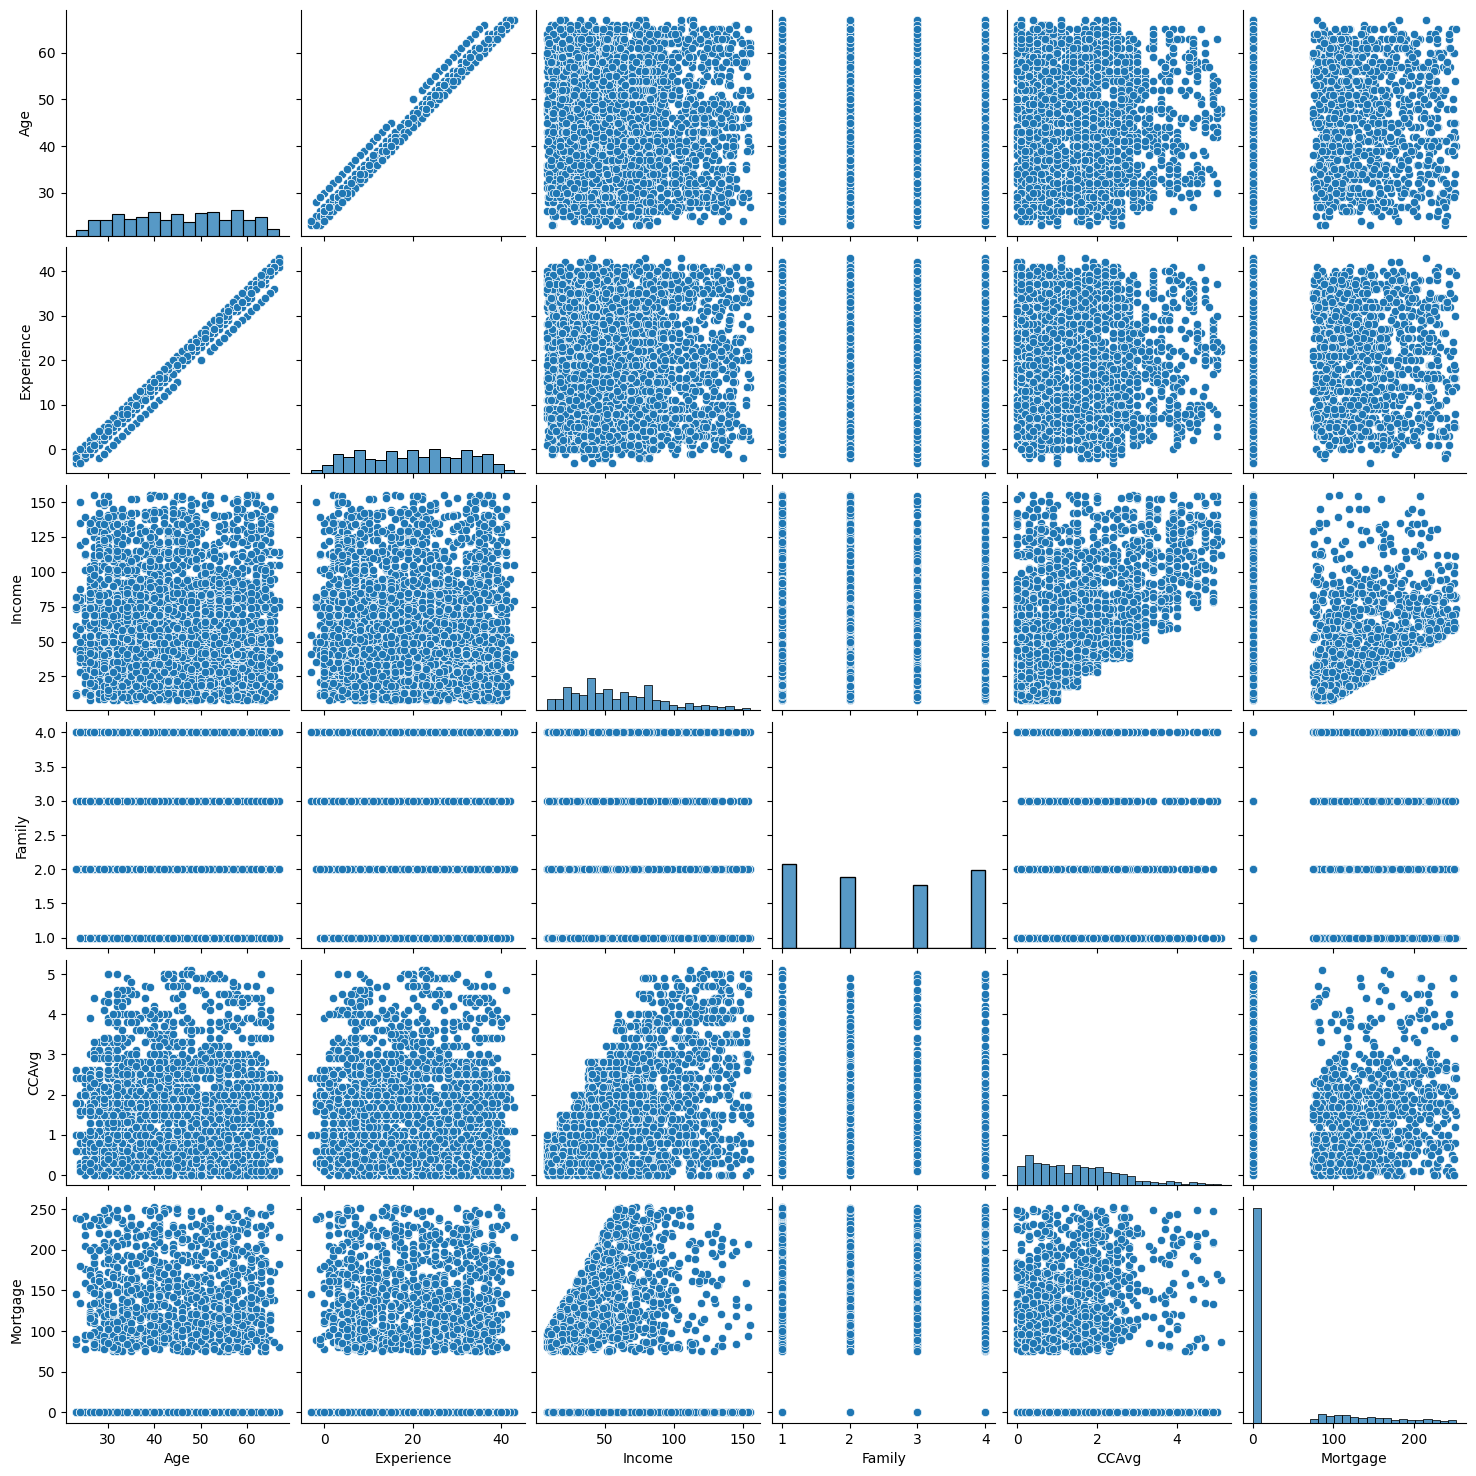

In [ ]:
sns.pairplot(loan_df[num_cols])

<Axes: >

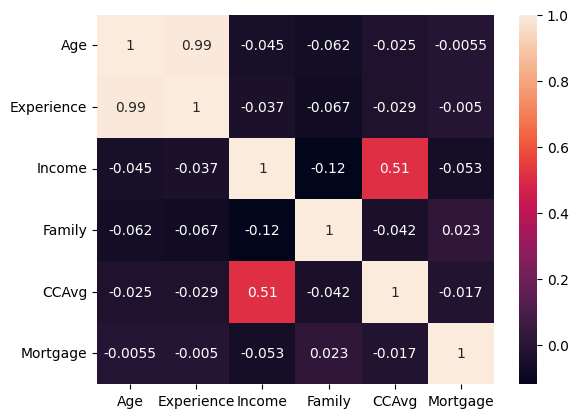

In [ ]:
pearson = loan_df[num_cols].corr()

sns.heatmap(pearson, annot=True)

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.
---
## Numericas:
Age: No hay diferencia entre las personas con o sin prestamo

Experiance: No hay diferencia entre las personas con o sin prestamo

Income: Las personas con prestamos tienen mayores ingresos

Family: No hay diferencia entre las personas con o sin prestamo

CCavg: Las personas con prestamos personales tienen mas deudas en tarjetas de credito

Mortgage: Las personas con credito personal son menos propensas a tener una hipoteca

## Categoricas
Education: People with more education are slighlty more likely to have a personal loan

Securities: No visible influence

CD Account: People with a deposit are more likely to have a personal loan

Online: No visible influence

Credit Card: No visible influence


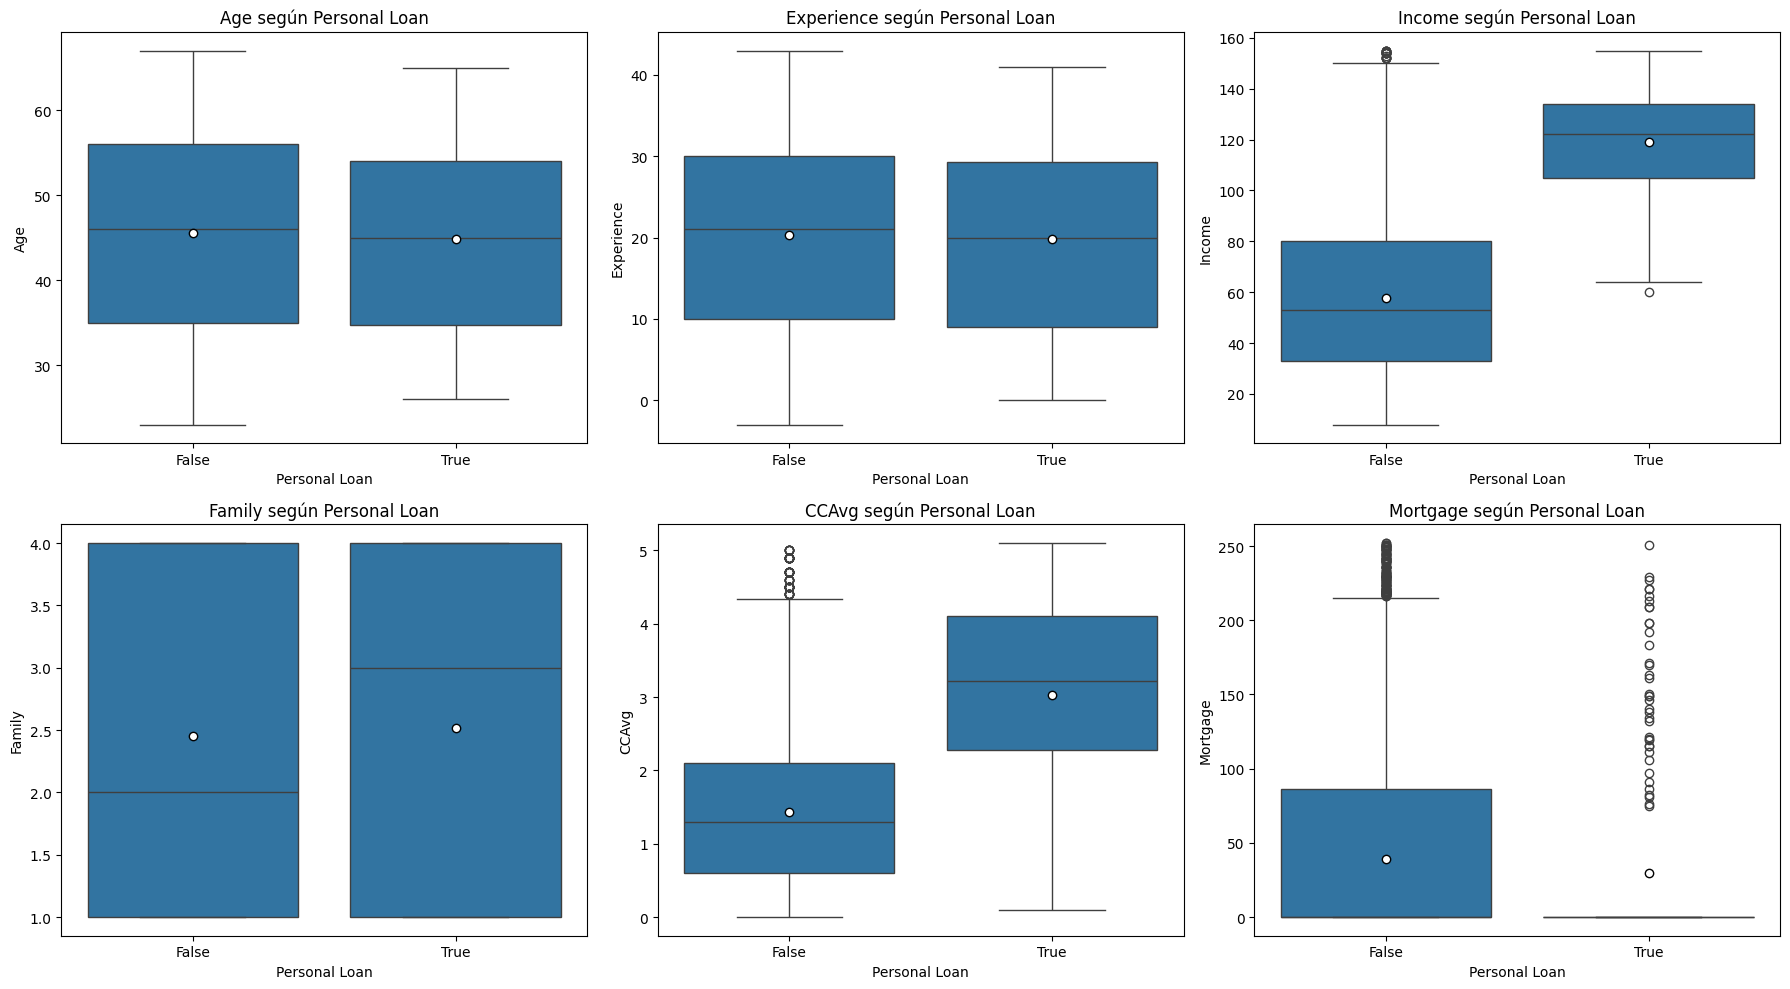

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, column in enumerate(num_cols):
    ax = axes[i]

    sns.boxplot(
        data=loan_df,
        x='Personal Loan',
        y=column,
        ax=ax,
        showmeans=True,
        meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
    )

    ax.set_title(f'{column} según Personal Loan')
    ax.set_xlabel('Personal Loan')
    ax.set_ylabel(column)

# Apagar los ejes que sobran en la cuadrícula
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

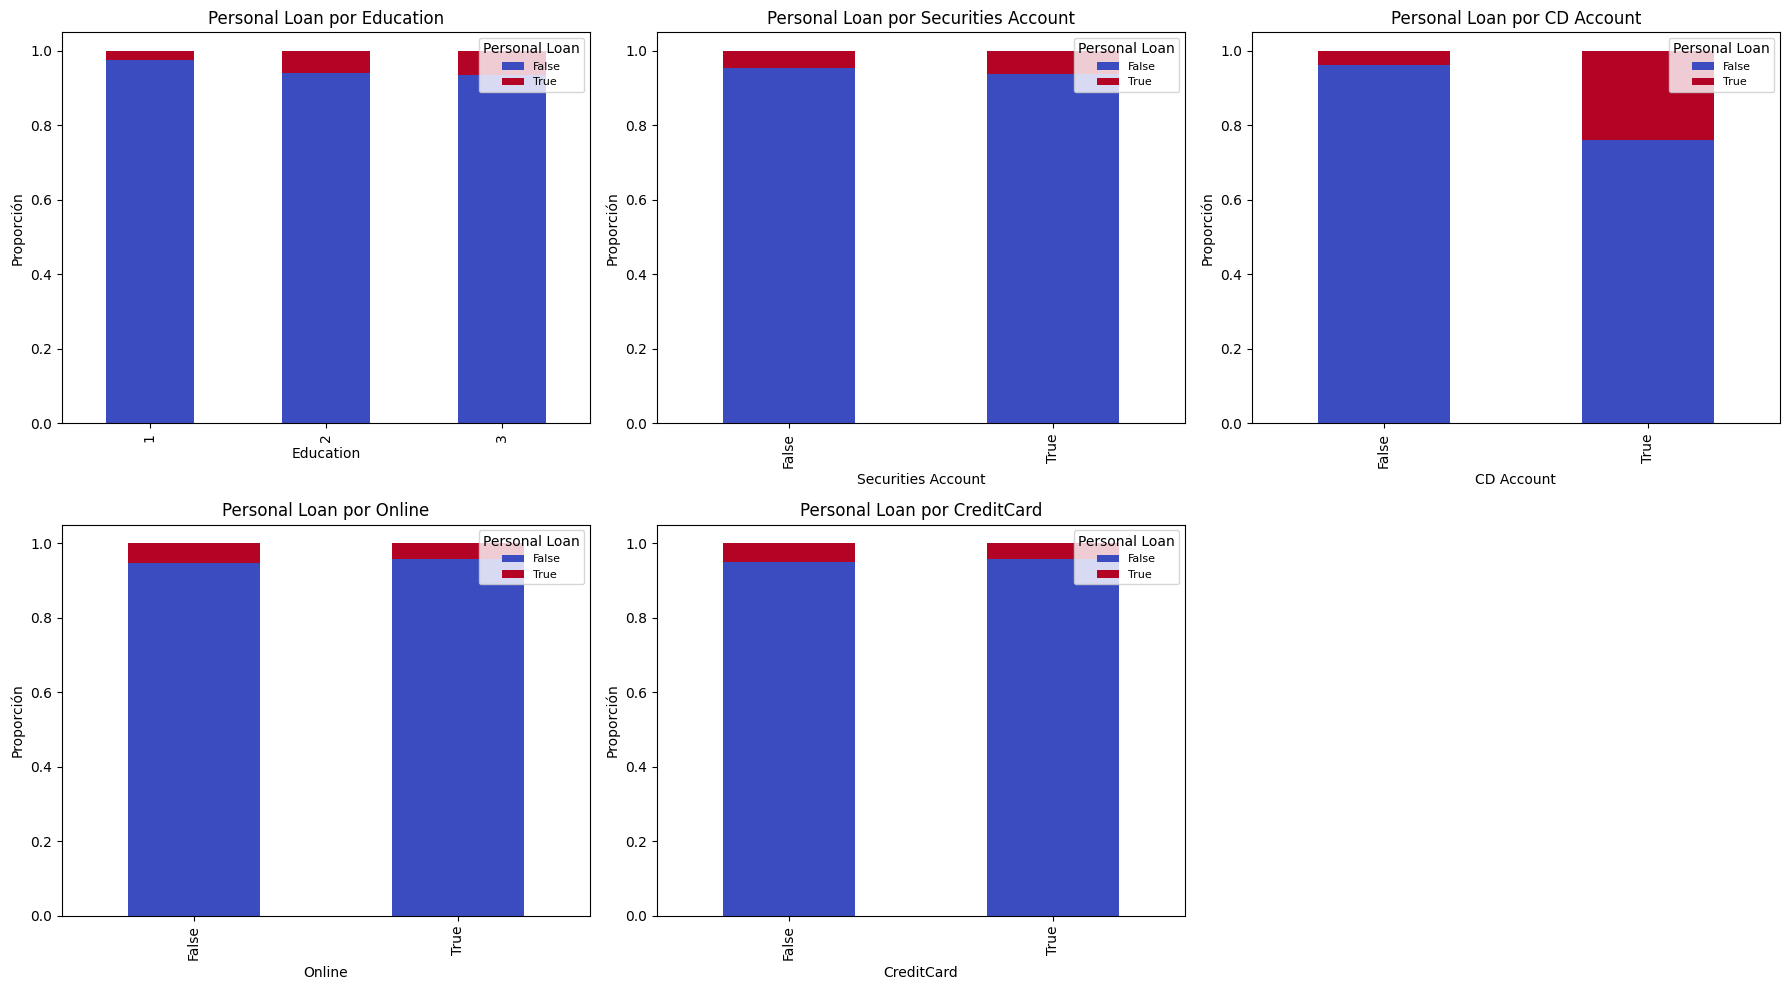

In [ ]:
stack_cols = [c for c in cat_cols if c not in ('ZIP Code', 'Personal Loan')]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, column in enumerate(stack_cols):
    ax = axes[i]

    # normalize='index' -> cada barra suma 1, así se ve la proporción y no el conteo
    prop = pd.crosstab(loan_df[column], loan_df['Personal Loan'], normalize='index')
    prop.plot(kind='bar', stacked=True, ax=ax, colormap='coolwarm')

    ax.set_title(f'Personal Loan por {column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Proporción')
    ax.legend(title='Personal Loan', loc='upper right', fontsize=8)

for j in range(len(stack_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---